# Módulo B: Series de tiempo (demanda diaria)

> ¿Cuántas órdenes recibirá Olist cada día durante las próximas 4 semanas?

- **Serie:** órdenes por día según `order_purchase_timestamp`, construida en SQL incluyendo días sin órdenes.
- **Partición:** prueba = últimas 8 semanas del período útil (Módulo 0); validación walk-forward
  (origen móvil, horizonte 28 días) sobre los datos anteriores.

**Responsable:** _(nombre)_

In [1]:
# Configuración común: imports, conexión solo lectura y estilo de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from olist import conectar, consulta, RANDOM_STATE
from olist import config
from olist.graficos import estilo, guardar

estilo()
np.random.seed(RANDOM_STATE)
con = conectar()  # read_only=True: la base cruda no se modifica

from olist import series as ts
import joblib
from statsmodels.tsa.statespace.sarimax import SARIMAX

## 1. Construcción de la serie

594 días, de 2017-01-05 a 2018-08-21; días en cero: 0
Ajuste/validación: 2017-01-05 a 2018-06-26; prueba reservada: 2018-06-27 a 2018-08-21


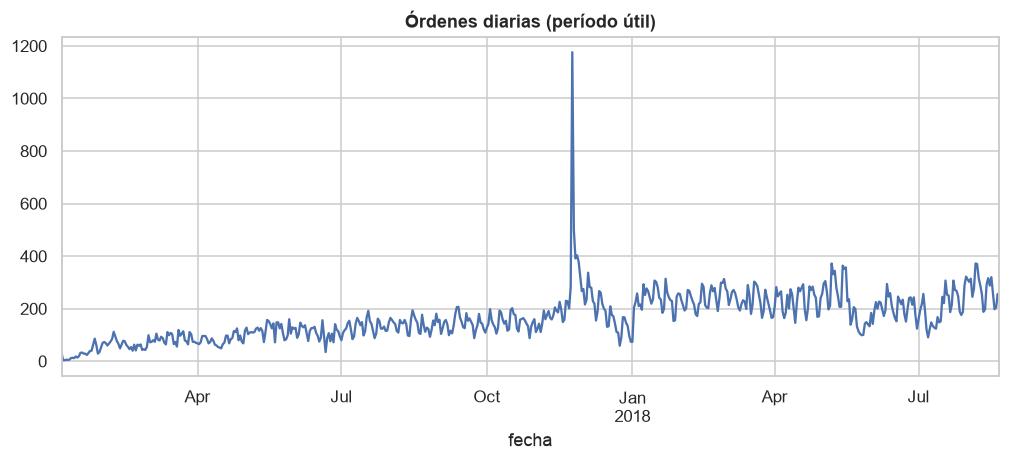

In [2]:
df = consulta(con, "B_series/serie_diaria.sql", [config.FECHA_INICIO_UTIL, config.FECHA_FIN_UTIL])
y = df.set_index(pd.DatetimeIndex(df["fecha"]).rename("fecha"))["ordenes"].astype(float).asfreq("D")
y_trval, y_prueba = ts.separar_prueba(y)
print(f"{len(y)} días, de {y.index.min().date()} a {y.index.max().date()}; días en cero: {(y == 0).sum()}")
print(f"Ajuste/validación: {y_trval.index.min().date()} a {y_trval.index.max().date()}; prueba reservada: {y_prueba.index.min().date()} a {y_prueba.index.max().date()}")
y.plot(title="Órdenes diarias (período útil)");

## 2. Análisis de la serie

Tendencia, estacionalidad semanal, ACF/PACF, estacionariedad (ADF/KPSS) y descomposición.
Identificar y tratar atípicos (Black Friday 2017, festivos, paros) y justificar si se modelan, marcan o excluyen.

,agrupacion,periodo,dias_observados,media_ordenes,mediana_ordenes,total_ordenes
0,dia_semana,0,77,134.3,125,10344.0
1,dia_semana,1,77,181.4,161,13971.0
2,dia_semana,2,77,178.7,168,13759.0
3,dia_semana,3,76,173.8,157,13212.0
4,dia_semana,4,77,163.4,144,12583.0
5,dia_semana,5,77,159.0,141,12246.0
6,dia_semana,6,77,122.3,109,9417.0
7,mes,2017-01,27,29.6,29,800.0
8,mes,2017-02,28,63.6,63,1780.0
9,mes,2017-03,31,86.5,80,2682.0


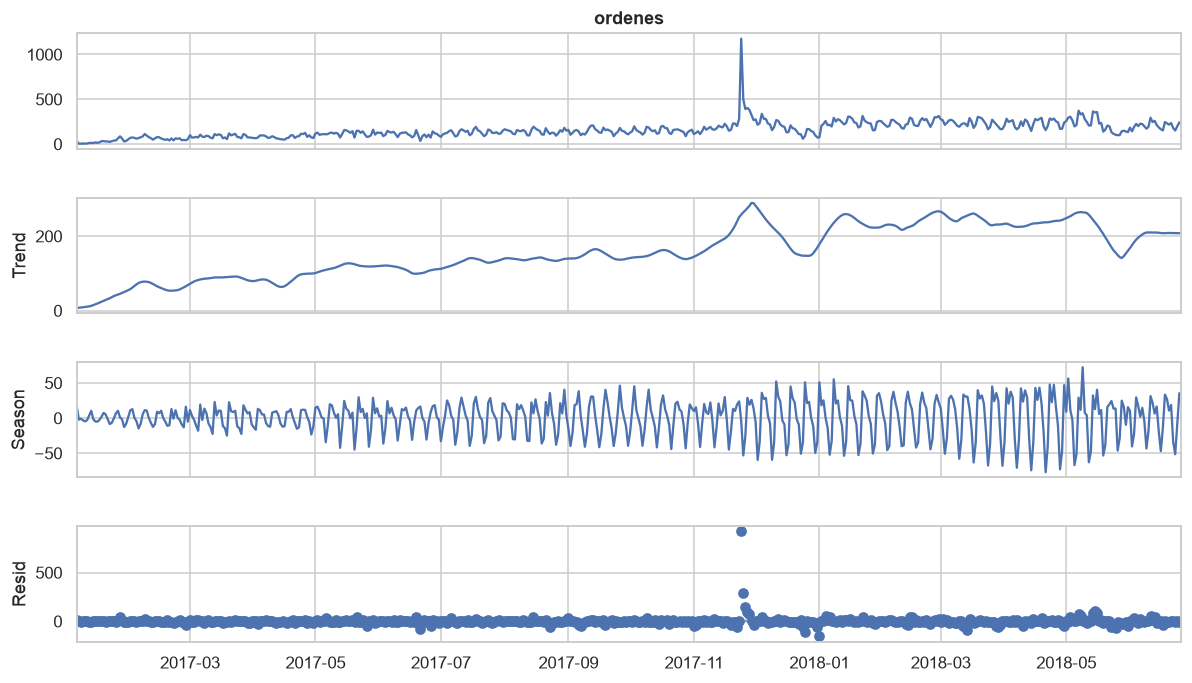

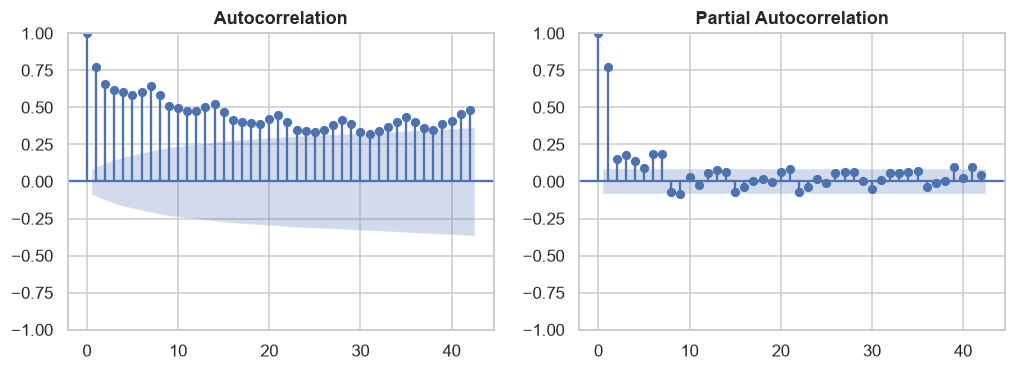

ADF  p-valor (H0: raíz unitaria): 0.0172
KPSS p-valor (H0: estacionaria en nivel): 0.01
ACF por rezago: {1: np.float64(0.771), 7: np.float64(0.641), 14: np.float64(0.522), 28: np.float64(0.415)}
PACF por rezago: {1: np.float64(0.773), 7: np.float64(0.191), 14: np.float64(0.067), 28: np.float64(0.072)}


/var/folders/69/50jgs3sd6zvc24ygmj4d62qr0000gn/T/ipykernel_74453/1394631914.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_p = kpss(y_trval, regression="c", nlags="auto", result_object=False)[1]


,count,mean,median,min,max
evento,,,,,
black_friday_2017,15,344.0,275.0,149,1176
paro_camioneros_2018,12,141.9,136.5,99,206
recuperacion_post_paro,7,201.0,200.0,142,227
referencia_black_friday,14,173.1,174.5,111,226
referencia_pre_paro,20,267.7,260.5,139,372


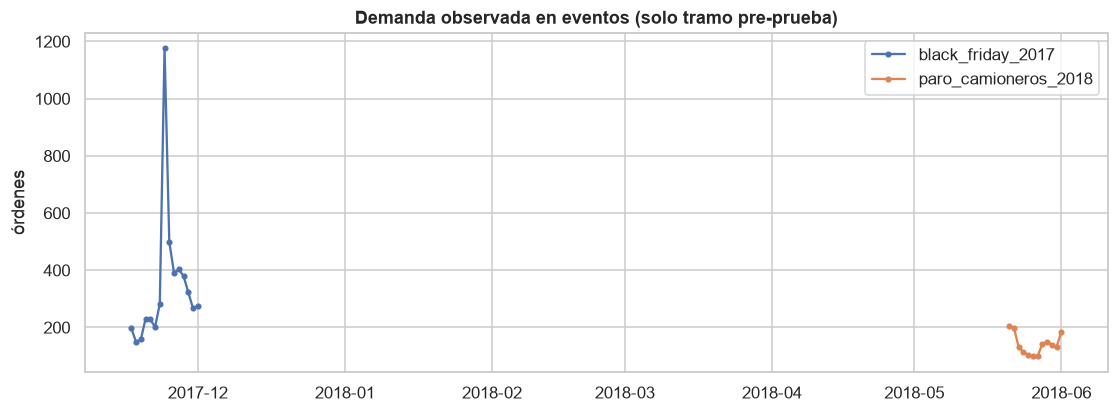

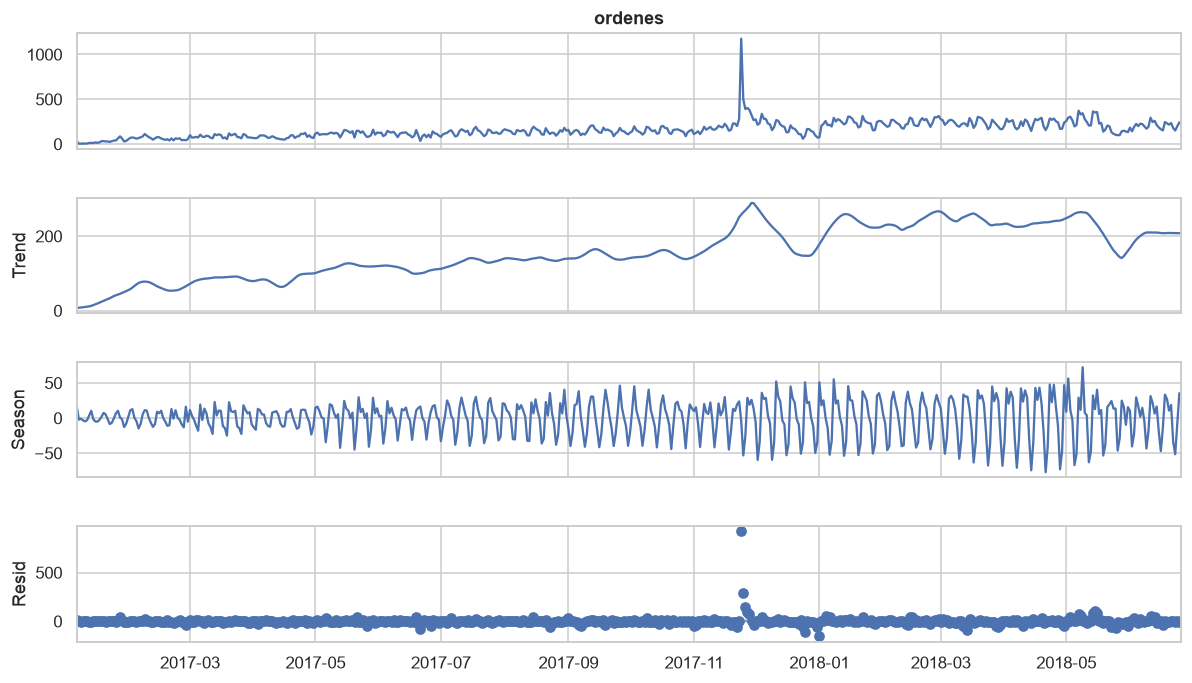

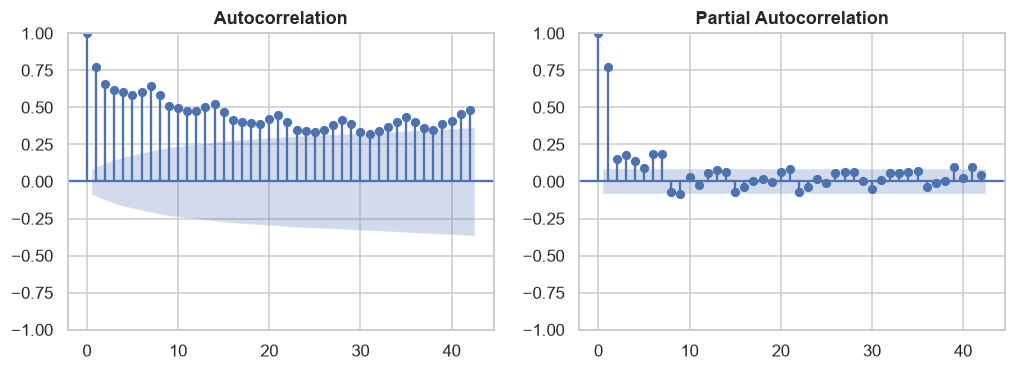

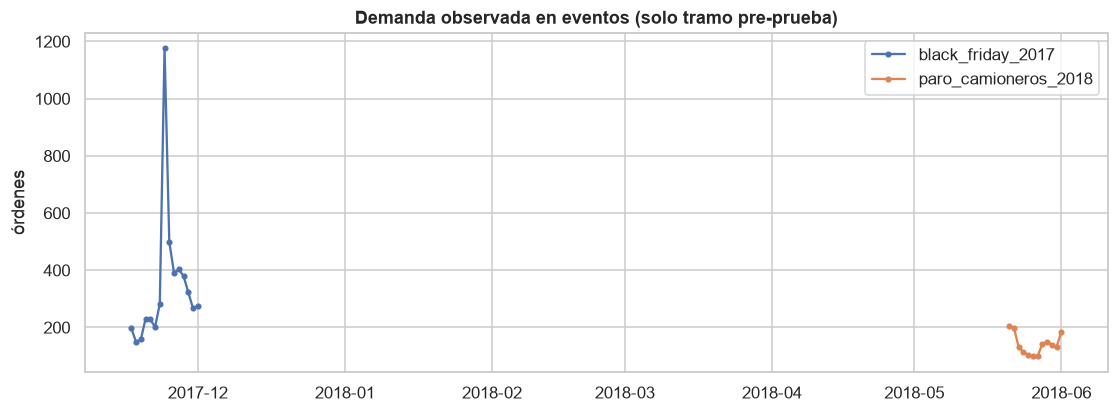

In [3]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

# El análisis de selección usa solo el tramo anterior a la prueba.
calendario_resumen = consulta(
    con, "B_series/analisis_calendario.sql",
    [y_trval.index.min().date().isoformat(), (y_trval.index.max() + pd.Timedelta(days=1)).date().isoformat()],
)
display(calendario_resumen)

stl = STL(y_trval, period=config.ESTACIONALIDAD, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7)
guardar(fig, "stl", "B_series")
display(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(y_trval, lags=42, ax=axes[0]); plot_pacf(y_trval, lags=42, ax=axes[1])
guardar(fig, "acf_pacf", "B_series")
display(fig)

adf_p = adfuller(y_trval, result_object=False)[1]
kpss_p = kpss(y_trval, regression="c", nlags="auto", result_object=False)[1]
print("ADF  p-valor (H0: raíz unitaria):", round(adf_p, 4))
print("KPSS p-valor (H0: estacionaria en nivel):", round(kpss_p, 4))
lags_interes = [1, 7, 14, 28]
print("ACF por rezago:", dict(zip(lags_interes, acf(y_trval, nlags=28, fft=True)[lags_interes].round(3))))
print("PACF por rezago:", dict(zip(lags_interes, pacf(y_trval, nlags=28)[lags_interes].round(3))))

eventos = consulta(
    con,
    "B_series/eventos_especiales.sql",
    [y_trval.index.min().date().isoformat(), (y_trval.index.max() + pd.Timedelta(days=1)).date().isoformat(),
     "2017-11-17", "2017-12-01", "2017-11-03", "2017-11-16",
     "2018-05-21", "2018-06-01", "2018-05-01", "2018-05-20", "2018-06-02", "2018-06-08"],
)
resumen_eventos = eventos.groupby("evento")["ordenes"].agg(["count", "mean", "median", "min", "max"]).round(1)
display(resumen_eventos)
fig, ax = plt.subplots(figsize=(12, 4))
for evento in ["black_friday_2017", "paro_camioneros_2018"]:
    datos = eventos[eventos["evento"] == evento]
    ax.plot(datos["fecha"], datos["ordenes"], marker="o", ms=3, label=evento)
ax.set(title="Demanda observada en eventos (solo tramo pre-prueba)", ylabel="órdenes")
ax.legend()
guardar(fig, "eventos_especiales", "B_series")
display(fig)

La tendencia mensual aumenta desde 800 órdenes en enero de 2017 hasta 7.544 en noviembre; enero y marzo de 2018 superan 7.200. La media por día de semana muestra oscilación semanal: domingo 134,3 y sábado 122,3 frente a lunes 181,4 y martes 178,7. La ACF en el rezago 7 es 0,641 (rezago 1: 0,771), coherente con persistencia semanal. En el tramo pre-prueba, ADF da p=0,0172 y rechaza raíz unitaria al 5 %, mientras KPSS da p≤0,01 y rechaza estacionariedad en nivel; como sus hipótesis nulas difieren, el resultado es mixto y puede reflejar tendencia o cambios estructurales. Por ello se conserva el ciclo semanal y se comparan pronósticos fuera de muestra, sin imponer estacionariedad en nivel. STL muestra tendencia, componente semanal y residuo.

**Tratamiento acordado:** conservar todas las observaciones. Modelar Black Friday y festivos mediante variables calendario conocidas de antemano (`semana_black_friday`, `festivo` y calendario); no excluir picos de demanda. El 24-nov-2017 registra 1.176 órdenes, frente a una media de 173,1 y máximo de 226 en los 14 días previos. El paro de camioneros (21-may a 1-jun-2018) baja a 141,9 órdenes/día frente a 267,7 del 1 al 20 de mayo, y la media del 2 al 8 de junio es 201,0. Se conservan y marcan para interpretar errores, pero no se usa un indicador de paro futuro no conocido al emitir el pronóstico; es un shock no recurrente.

## 3. Partición: prueba y walk-forward

In [4]:
n_pliegues = 8
pliegues = list(
    ts.walk_forward(y_trval, n_pliegues=n_pliegues, horizonte=config.HORIZONTE,
                    paso=config.HORIZONTE)
)
pliegues_seleccion = pliegues[:-2]
pliegues_calibracion = pliegues[-2:]
print("Entrenamiento+validación:", y_trval.index.min().date(), "→", y_trval.index.max().date())
print("Prueba (no tocar hasta el final):", y_prueba.index.min().date(), "→", y_prueba.index.max().date())
print(f"{len(pliegues_seleccion)} pliegues no solapados para selección; {len(pliegues_calibracion)} reservados para calibrar intervalos.")
pd.DataFrame([{"pliegue": p.numero, "origen": p.origen.date(), "n_entrenamiento": len(p.entrenamiento),
               "validacion": f"{p.validacion.index[0].date()} → {p.validacion.index[-1].date()}"} for p in pliegues])

Entrenamiento+validación: 2017-01-05 → 2018-06-26
Prueba (no tocar hasta el final): 2018-06-27 → 2018-08-21
6 pliegues no solapados para selección; 2 reservados para calibrar intervalos.


,pliegue,origen,n_entrenamiento,validacion
0,0,2017-11-14,314,2017-11-15 → 2017-12-12
1,1,2017-12-12,342,2017-12-13 → 2018-01-09
2,2,2018-01-09,370,2018-01-10 → 2018-02-06
3,3,2018-02-06,398,2018-02-07 → 2018-03-06
4,4,2018-03-06,426,2018-03-07 → 2018-04-03
5,5,2018-04-03,454,2018-04-04 → 2018-05-01
6,6,2018-05-01,482,2018-05-02 → 2018-05-29
7,7,2018-05-29,510,2018-05-30 → 2018-06-26


## 4. Baselines (ingenuo e ingenuo estacional)

In [5]:
resultados_cv = []
for p in pliegues:
    for nombre, funcion in [("ingenuo", ts.pronostico_ingenuo),
                            ("ingenuo_estacional", ts.pronostico_ingenuo_estacional)]:
        pred = funcion(p.entrenamiento, config.HORIZONTE)
        fila = ts.a_formato_largo(nombre, p.origen, p.validacion, pred)
        fila["pliegue"] = p.numero
        resultados_cv.append(fila)
resultados_cv = pd.concat(resultados_cv, ignore_index=True)
def resumir_pliegues(datos):
    por_pliegue = datos.groupby(["modelo", "pliegue"]).apply(
        lambda grupo: pd.Series(ts.metricas(grupo["y"], grupo["yhat"])),
        include_groups=False,
    )
    return por_pliegue.groupby("modelo").agg(["mean", "std"]).round(2)

display(resumir_pliegues(resultados_cv[resultados_cv["pliegue"] < len(pliegues_seleccion)]))

MAE          RMSE         sMAPE       
                     mean    std   mean    std   mean    std
modelo                                                      
ingenuo             60.67  33.98  86.07  67.66  25.24  14.23
ingenuo_estacional  52.17  35.72  76.56  73.60  21.81  13.25

## 5. Modelo estadístico: SARIMA estacional

Se ajusta SARIMA(1,1,1)(1,0,1)[7] en cada origen walk-forward. Los intervalos del 90 % se obtienen del modelo de espacio de estados; se truncan abajo en cero porque una demanda negativa no es interpretable.

In [6]:
sarima_resultados = []
sarima_intervalos = []
for p in pliegues:
    modelo_sarima = SARIMAX(
        p.entrenamiento.astype(float),
        order=(1, 1, 1), seasonal_order=(1, 0, 1, config.ESTACIONALIDAD),
        enforce_stationarity=False, enforce_invertibility=False,
    ).fit(disp=False, maxiter=150)
    pronostico = modelo_sarima.get_forecast(steps=config.HORIZONTE)
    pred = pronostico.predicted_mean.clip(lower=0)
    intervalo = pronostico.conf_int(alpha=0.10)
    fila = ts.a_formato_largo("sarima", p.origen, p.validacion, pred)
    fila["pliegue"] = p.numero
    sarima_resultados.append(fila)
    sarima_intervalos.append(pd.DataFrame({
        "modelo": "sarima", "pliegue": p.numero, "fecha": p.validacion.index,
        "y": p.validacion.to_numpy(),
        "inferior": np.maximum(intervalo.iloc[:, 0].to_numpy(), 0),
        "superior": intervalo.iloc[:, 1].to_numpy(),
    }))
sarima_resultados = pd.concat(sarima_resultados, ignore_index=True)
sarima_intervalos = pd.concat(sarima_intervalos, ignore_index=True)
resultados_cv = pd.concat([resultados_cv, sarima_resultados], ignore_index=True)
display(resumir_pliegues(sarima_resultados[sarima_resultados["pliegue"] < len(pliegues_seleccion)]))

MAE          RMSE         sMAPE       
         mean    std   mean    std   mean    std
modelo                                          
sarima  58.13  35.64  82.85  72.33  24.17  14.94

## 6. Modelo de ML: LightGBM con rezagos, medias móviles y calendario

Se comparan dos estrategias con las mismas familias de variables y ajuste walk-forward:
- **Recursiva:** se entrena un modelo de un paso y cada predicción se realimenta como rezago.
- **Directa agrupada:** un modelo predice los horizontes 1–28 usando rezagos del origen, calendario de la fecha objetivo y el paso adelante; no reutiliza objetivos futuros.

La búsqueda usa tres configuraciones prefijadas y solo los primeros seis pliegues; los dos pliegues más recientes quedan reservados para calibración de intervalos. La prueba no participa en ajuste ni selección.

In [7]:
candidatos = {
    "compacto": {"n_estimators": 250, "learning_rate": 0.03, "num_leaves": 7, "min_child_samples": 20},
    "base": {"n_estimators": 400, "learning_rate": 0.03, "num_leaves": 15, "min_child_samples": 10},
    "mayor_capacidad": {"n_estimators": 600, "learning_rate": 0.02, "num_leaves": 31, "min_child_samples": 20},
}
resultados_grid = []
for estrategia in ["recursivo", "directo"]:
    for nombre_parametros, parametros in candidatos.items():
        for p in pliegues_seleccion:
            if estrategia == "recursivo":
                modelo_lgbm = ts.entrenar_lightgbm(
                    p.entrenamiento, random_state=RANDOM_STATE, **parametros
                )
                pred = ts.pronostico_recursivo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
                nombre_modelo = f"lightgbm_recursivo_{nombre_parametros}"
            else:
                modelo_lgbm = ts.entrenar_lightgbm_directo(
                    p.entrenamiento, random_state=RANDOM_STATE, **parametros
                )
                pred = ts.pronostico_directo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
                nombre_modelo = f"lightgbm_directo_{nombre_parametros}"
            fila = ts.a_formato_largo(nombre_modelo, p.origen, p.validacion, pred.clip(lower=0))
            fila["pliegue"] = p.numero
            resultados_grid.append(fila)
resultados_grid = pd.concat(resultados_grid, ignore_index=True)

resumen_grid = []
for nombre, datos in resultados_grid.groupby("modelo"):
    por_pliegue = datos.groupby("pliegue").apply(
        lambda grupo: pd.Series(ts.metricas(grupo["y"], grupo["yhat"])),
        include_groups=False,
    )
    resumen_grid.append({
        "modelo": nombre,
        "MAE_media_folds": por_pliegue["MAE"].mean(),
        "MAE_std_folds": por_pliegue["MAE"].std(),
        "RMSE_media_folds": por_pliegue["RMSE"].mean(),
        "sMAPE_media_folds": por_pliegue["sMAPE"].mean(),
    })
resumen_grid = pd.DataFrame(resumen_grid).sort_values("MAE_media_folds")
display(resumen_grid.round(2))
mejores_estrategia = {
    estrategia: resumen_grid[resumen_grid["modelo"].str.startswith(f"lightgbm_{estrategia}_")].iloc[0]["modelo"]
    for estrategia in ["recursivo", "directo"]
}
parametros_elegidos = {
    nombre: candidatos[nombre.removeprefix(f"lightgbm_{estrategia}_")]
    for estrategia, nombre in mejores_estrategia.items()
}
print("Mejor configuración por estrategia:", mejores_estrategia)
print("Parámetros elegidos:", parametros_elegidos)

resultados_lgbm = []
calibracion_lgbm = []
for estrategia, nombre_modelo in mejores_estrategia.items():
    parametros = parametros_elegidos[nombre_modelo]
    for p in pliegues:
        if estrategia == "recursivo":
            modelo_lgbm = ts.entrenar_lightgbm(
                p.entrenamiento, random_state=RANDOM_STATE, **parametros
            )
            pred = ts.pronostico_recursivo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
        else:
            modelo_lgbm = ts.entrenar_lightgbm_directo(
                p.entrenamiento, random_state=RANDOM_STATE, **parametros
            )
            pred = ts.pronostico_directo(modelo_lgbm, p.entrenamiento, config.HORIZONTE)
        fila = ts.a_formato_largo(f"lightgbm_{estrategia}", p.origen, p.validacion, pred.clip(lower=0))
        fila["pliegue"] = p.numero
        resultados_lgbm.append(fila)
        if p.numero >= len(pliegues_seleccion):
            calibracion_lgbm.append(fila)
resultados_lgbm = pd.concat(resultados_lgbm, ignore_index=True)
calibracion_lgbm = pd.concat(calibracion_lgbm, ignore_index=True)
resultados_cv = pd.concat([resultados_cv, resultados_lgbm], ignore_index=True)
display(resumir_pliegues(resultados_lgbm[resultados_lgbm["pliegue"] < len(pliegues_seleccion)]))

,modelo,MAE_media_folds,MAE_std_folds,RMSE_media_folds,sMAPE_media_folds
1,lightgbm_directo_compacto,63.26,53.83,91.95,26.97
2,lightgbm_directo_mayor_capacidad,64.17,56.67,95.52,26.76
0,lightgbm_directo_base,64.38,56.52,95.80,26.74
4,lightgbm_recursivo_compacto,74.28,44.12,100.36,30.80
5,lightgbm_recursivo_mayor_capacidad,74.51,45.96,101.93,30.37
3,lightgbm_recursivo_base,99.07,54.23,128.95,36.86


Mejor configuración por estrategia: {'recursivo': 'lightgbm_recursivo_compacto', 'directo': 'lightgbm_directo_compacto'}
Parámetros elegidos: {'lightgbm_recursivo_compacto': {'n_estimators': 250, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 20}, 'lightgbm_directo_compacto': {'n_estimators': 250, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 20}}


MAE           RMSE         sMAPE       
                     mean    std    mean    std   mean    std
modelo                                                       
lightgbm_directo    63.26  53.83   91.95  90.23  26.97  24.28
lightgbm_recursivo  74.28  44.12  100.36  76.03  30.80  17.84

## 7. Métricas por horizonte

MAE           RMSE         sMAPE       
                     mean    std    mean    std   mean    std
modelo                                                       
ingenuo             60.67  33.98   86.07  67.66  25.24  14.23
ingenuo_estacional  52.17  35.72   76.56  73.60  21.81  13.25
lightgbm_directo    63.26  53.83   91.95  90.23  26.97  24.28
lightgbm_recursivo  74.28  44.12  100.36  76.03  30.80  17.84
sarima              58.13  35.64   82.85  72.33  24.17  14.94

Modelo elegido por MAE medio en los seis pliegues de selección: ingenuo_estacional


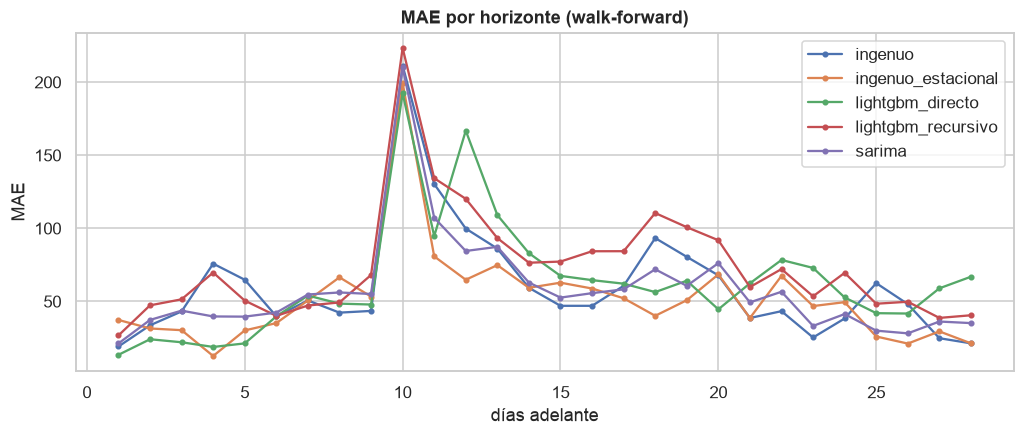

,modelo,h,MAE,RMSE,sMAPE
0,ingenuo,1,19.166667,22.616366,7.741352
1,ingenuo,2,33.666667,36.801268,14.180370
2,ingenuo,3,43.166667,50.476067,18.766531
3,ingenuo,4,75.833333,82.130993,36.508058
4,ingenuo,5,64.833333,74.658110,30.843016
...,...,...,...,...,...
135,sarima,24,41.366461,57.395044,18.263928
136,sarima,25,30.001129,36.527210,14.503931
137,sarima,26,28.156497,35.696879,13.290988
138,sarima,27,36.242101,39.004791,14.335575


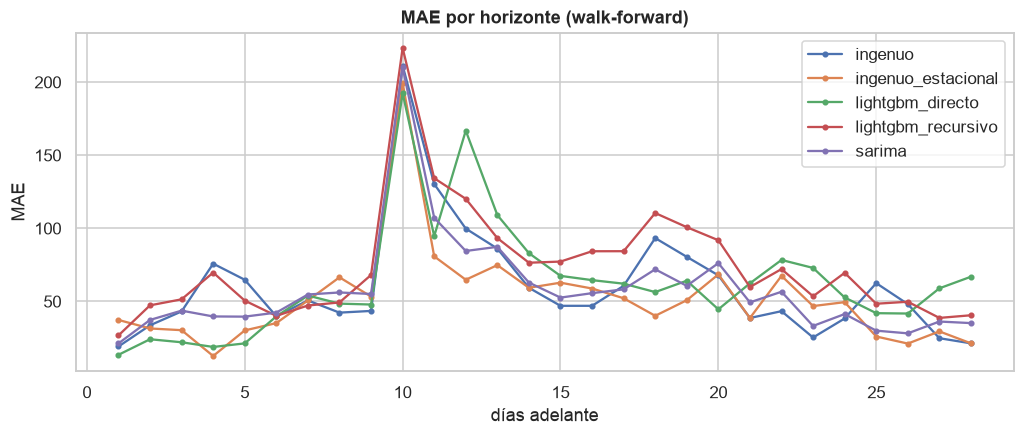

In [8]:
modelos_seleccion = ["ingenuo", "ingenuo_estacional", "sarima", "lightgbm_recursivo", "lightgbm_directo"]
datos_seleccion = resultados_cv[
    resultados_cv["modelo"].isin(modelos_seleccion)
    & (resultados_cv["pliegue"] < len(pliegues_seleccion))
].copy()
resumen_seleccion = resumir_pliegues(datos_seleccion)
display(resumen_seleccion)
ganador_cv = resumen_seleccion[("MAE", "mean")].idxmin()
print("Modelo elegido por MAE medio en los seis pliegues de selección:", ganador_cv)
por_h = ts.metricas_por_horizonte(datos_seleccion)
fig, ax = plt.subplots()
for nombre, g in por_h.groupby("modelo"):
    ax.plot(g["h"], g["MAE"], marker="o", ms=3, label=nombre)
ax.set(title="MAE por horizonte (walk-forward)", xlabel="días adelante", ylabel="MAE")
ax.legend()
guardar(fig, "mae_por_horizonte", "B_series")
display(fig)
display(por_h)

## 8. Incertidumbre: intervalos de predicción y cobertura empírica

Para SARIMA se conservan los intervalos del 90 % del modelo de espacio de estados. Para LightGBM se calibra un intervalo conformal simétrico con el percentil empírico 90 de errores absolutos de los dos pliegues recientes reservados. La cobertura y el ancho se reportan en la prueba; la deriva temporal puede degradar la cobertura.

In [9]:
cuantiles_error = {}
for estrategia in ["recursivo", "directo"]:
    errores = calibracion_lgbm.loc[
        calibracion_lgbm["modelo"] == f"lightgbm_{estrategia}", "y"
    ].to_numpy() - calibracion_lgbm.loc[
        calibracion_lgbm["modelo"] == f"lightgbm_{estrategia}", "yhat"
    ].to_numpy()
    cuantiles_error[estrategia] = np.quantile(np.abs(errores), 0.90, method="higher")
print("Cuantiles conformales absolutos, calibración reservada:", cuantiles_error)
display(sarima_intervalos[sarima_intervalos["pliegue"] >= len(pliegues_seleccion)].groupby("pliegue").apply(
    lambda grupo: pd.Series({
        "cobertura_SARIMA": ((grupo["y"] >= grupo["inferior"]) & (grupo["y"] <= grupo["superior"])).mean(),
        "ancho_medio": (grupo["superior"] - grupo["inferior"]).mean(),
    }), include_groups=False
).round(3))

Cuantiles conformales absolutos, calibración reservada: {'recursivo': np.float64(116.27138838869519), 'directo': np.float64(106.85753305069869)}


,cobertura_SARIMA,ancho_medio
pliegue,,
6,0.75,201.979
7,1.00,247.387


## 9. Evaluación final en prueba (una sola vez)

La selección queda congelada con los seis pliegues walk-forward anteriores. Esta sección evalúa el bloque final de 56 días una sola vez; no se reajustan hiperparámetros con esos resultados.

,MAE,RMSE,sMAPE
sarima,43.35,53.60,19.84
lightgbm_recursivo,49.75,60.09,22.76
ingenuo_estacional,51.79,63.48,23.70
lightgbm_directo,55.14,65.28,25.20
ingenuo,57.43,69.21,25.96


Selección previa a la prueba: ingenuo_estacional
Artefacto para D: /Users/mac/Downloads/Universidad/Semestre 8/Aprendizaje Automatico/Taller-ML/models/lightgbm_series.joblib estrategia: directo
Cobertura prueba 90 %: SARIMA=100.0%; LightGBM conformal=92.9%; ancho medio LightGBM=213.7


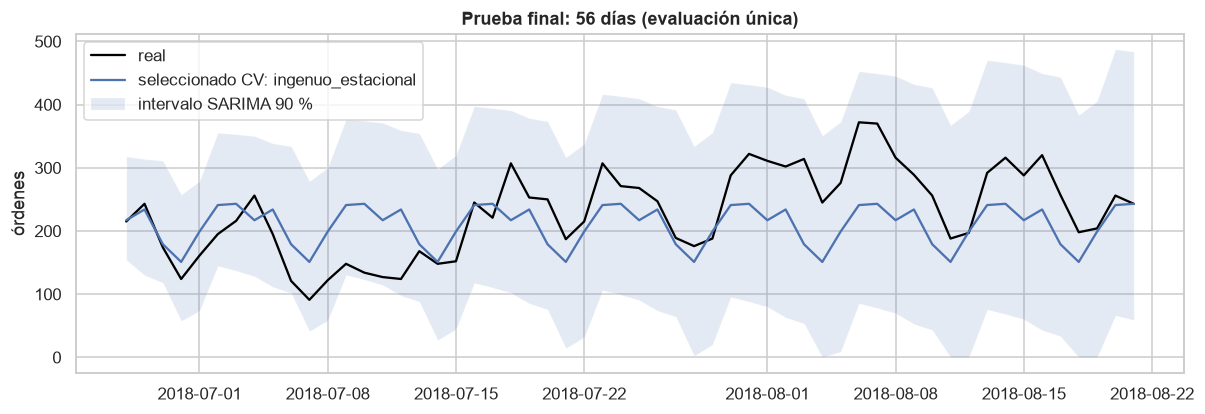

,modelo,h,MAE,RMSE,sMAPE
0,ingenuo,1,28.000000,28.000000,12.227074
1,ingenuo,2,0.000000,0.000000,0.000000
2,ingenuo,3,69.000000,69.000000,33.093525
3,ingenuo,4,119.000000,119.000000,64.850136
4,ingenuo,5,82.000000,82.000000,40.594059
...,...,...,...,...,...
275,sarima,52,18.444689,18.444689,7.444048
276,sarima,53,21.417592,21.417592,11.435450
277,sarima,54,6.984490,6.984490,3.483402
278,sarima,55,20.993133,20.993133,7.877450


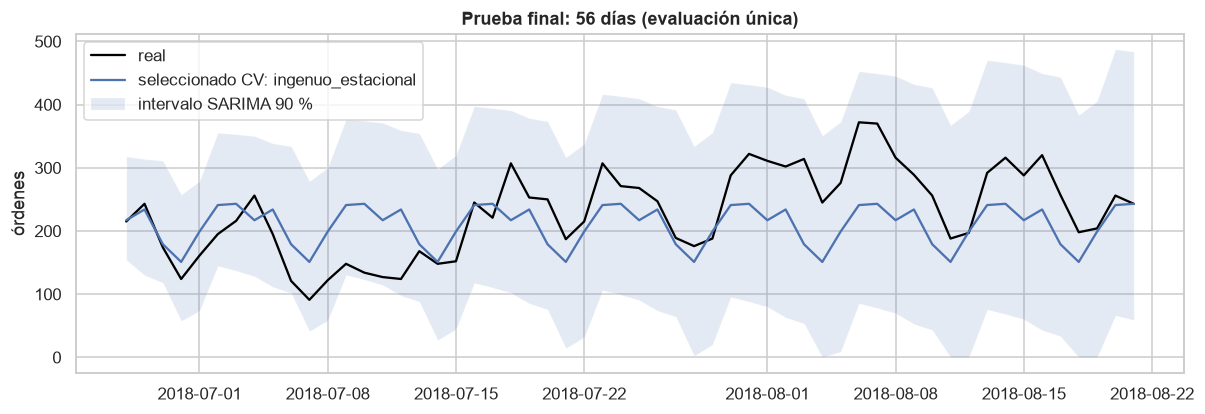

In [10]:
resultados_prueba = {
    "ingenuo": ts.pronostico_ingenuo(y_trval, len(y_prueba)).to_numpy(),
    "ingenuo_estacional": ts.pronostico_ingenuo_estacional(y_trval, len(y_prueba)).to_numpy(),
}

modelo_sarima_final = SARIMAX(
    y_trval.astype(float), order=(1, 1, 1),
    seasonal_order=(1, 0, 1, config.ESTACIONALIDAD),
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False, maxiter=150)
pronostico_sarima_final = modelo_sarima_final.get_forecast(steps=len(y_prueba))
resultados_prueba["sarima"] = pronostico_sarima_final.predicted_mean.clip(lower=0).to_numpy()
intervalo_sarima_prueba = pronostico_sarima_final.conf_int(alpha=0.10)

modelos_finales_lgbm = {}
for estrategia in ["recursivo", "directo"]:
    nombre = mejores_estrategia[estrategia]
    parametros = parametros_elegidos[nombre]
    if estrategia == "recursivo":
        modelo_final = ts.entrenar_lightgbm(y_trval, random_state=RANDOM_STATE, **parametros)
        prediccion_final = ts.pronostico_recursivo(modelo_final, y_trval, len(y_prueba))
    else:
        modelo_final = ts.entrenar_lightgbm_directo(y_trval, random_state=RANDOM_STATE, **parametros)
        prediccion_final = ts.pronostico_directo(modelo_final, y_trval, len(y_prueba))
    modelos_finales_lgbm[estrategia] = modelo_final
    resultados_prueba[f"lightgbm_{estrategia}"] = prediccion_final.clip(lower=0).to_numpy()

tabla_prueba = pd.DataFrame(
    {nombre: ts.metricas(y_prueba.to_numpy(), pred) for nombre, pred in resultados_prueba.items()}
).T.sort_values("MAE")
display(tabla_prueba.round(2))
print("Selección previa a la prueba:", ganador_cv)

ganador_lgbm = min(
    ["recursivo", "directo"],
    key=lambda estrategia: resumen_seleccion.loc[f"lightgbm_{estrategia}", ("MAE", "mean")],
)
modelo_lgbm_guardado = modelos_finales_lgbm[ganador_lgbm]
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
ruta_modelo = config.MODELS_DIR / "lightgbm_series.joblib"
joblib.dump({
    "modelo": modelo_lgbm_guardado,
    "estrategia": ganador_lgbm,
    "parametros": parametros_elegidos[mejores_estrategia[ganador_lgbm]],
    "features": list(modelo_lgbm_guardado.feature_name_),
    "fecha_corte_entrenamiento": y_trval.index.max().isoformat(),
}, ruta_modelo)
print("Artefacto para D:", ruta_modelo, "estrategia:", ganador_lgbm)

q_intervalo = cuantiles_error[ganador_lgbm]
pred_lgbm_prueba = resultados_prueba[f"lightgbm_{ganador_lgbm}"]
limite_inferior_lgbm = np.maximum(pred_lgbm_prueba - q_intervalo, 0)
limite_superior_lgbm = pred_lgbm_prueba + q_intervalo
cobertura_lgbm = ((y_prueba.to_numpy() >= limite_inferior_lgbm)
                   & (y_prueba.to_numpy() <= limite_superior_lgbm)).mean()
cobertura_sarima = (
    (y_prueba.to_numpy() >= np.maximum(intervalo_sarima_prueba.iloc[:, 0].to_numpy(), 0))
    & (y_prueba.to_numpy() <= intervalo_sarima_prueba.iloc[:, 1].to_numpy())
).mean()
print(f"Cobertura prueba 90 %: SARIMA={cobertura_sarima:.1%}; LightGBM conformal={cobertura_lgbm:.1%}; "
      f"ancho medio LightGBM={np.mean(limite_superior_lgbm - limite_inferior_lgbm):.1f}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y_prueba.index, y_prueba, color="black", label="real")
ax.plot(y_prueba.index, resultados_prueba[ganador_cv], label=f"seleccionado CV: {ganador_cv}")
ax.fill_between(y_prueba.index, np.maximum(intervalo_sarima_prueba.iloc[:, 0], 0),
                intervalo_sarima_prueba.iloc[:, 1], alpha=0.15, label="intervalo SARIMA 90 %")
ax.set(title="Prueba final: 56 días (evaluación única)", ylabel="órdenes")
ax.legend()
guardar(fig, "prueba_final", "B_series")
display(fig)
metricas_horizonte_prueba = ts.metricas_por_horizonte(
    pd.concat([
        ts.a_formato_largo(nombre, y_prueba.index[0] - pd.Timedelta(days=1), y_prueba, pd.Series(pred, index=y_prueba.index))
        for nombre, pred in resultados_prueba.items()
    ], ignore_index=True)
)
display(metricas_horizonte_prueba)

## Conclusiones del Módulo B

El ranking se determinó con los seis pliegues de selección; la prueba final solo estima desempeño fuera de muestra. Debe compararse la tabla final con el ingenuo estacional y reportarse cualquier pérdida sin reinterpretar el modelo a posteriori. La tabla por horizonte muestra si el error aumenta a medida que se pronostica más lejos. La cobertura real del 90 % y el ancho de los intervalos informan su utilidad operativa; ambos pueden verse afectados por la deriva y por shocks no recurrentes como el paro.

In [11]:
con.close()